In [2]:
# 아나콘다 가상환경이니까, 설치 안 되어 있을 수 있으니 설치 시도

!pip install matplotlib
!pip install wordcloud

In [2]:
import pandas as pd
import glob # 윈도우 디렉터리 관련
import re # Regular Expression(정규표현식). 정제 관련
from functools import reduce
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords # 불용어 단어셋
from nltk.stem import WordNetLemmatizer # 표제어 추출
from collections import Counter # 단어 안 겹치게. 얼마나 나왔는지 빈도수 체크.
import matplotlib.pyplot as plt
from wordcloud import STOPWORDS, WordCloud

In [4]:
all_files = glob.glob('ch08_data/exportExcelData_*.xls')
all_files

['ch08_data\\exportExcelData_20261027150515.xls',
 'ch08_data\\exportExcelData_20261027150539.xls',
 'ch08_data\\exportExcelData_20261027150558.xls',
 'ch08_data\\exportExcelData_20261027150621.xls',
 'ch08_data\\exportExcelData_20261027162459.xls',
 'ch08_data\\exportExcelData_20261027162535.xls',
 'ch08_data\\exportExcelData_20261027162601.xls',
 'ch08_data\\exportExcelData_20261027162624.xls',
 'ch08_data\\exportExcelData_20261027162647.xls',
 'ch08_data\\exportExcelData_20261027162713.xls']

In [4]:
# No module named 'xlrd' 에러를 해결하기 위해 xlrd 라이브러리 설치
!pip install xlrd

In [5]:
all_files_data = [] # 저장할 리스트
for file in all_files:
    data_frame = pd.read_excel(file)
    all_files_data.append(data_frame)
all_files_data[0]

,Unnamed: 0,번호,제목,저자,출판사,출판일
0,NaN,1,Model my watershed: an investigation into the ...,"Marcum-Dietrich, Nanette; Kerlin, Steve; Hendr...",Taylor & Francis,2021
1,NaN,2,Architecting Time-Critical Big-Data Systems,"Basanta-Val, P.; Audsley, N. C.; Wellings, A. ...",unknown,2016
2,NaN,3,A Game Theoretic Approach for Addressing Domai...,"Raghavan, Krishnan",unknown,2022
3,NaN,4,Computation migration: a new approach to execu...,"Nunes, Rickey T. P.; Deshpande, Santosh L.",Inderscience,2018
4,NaN,5,A trust-based crowdfunding campaign marketing ...,"Baah-Peprah, Prince; Shneor, Rotem",Inderscience,2021
...,...,...,...,...,...,...
95,NaN,96,Big Data As an Enabler of Primary Education,unknown,Mary Ann Leibert,2016
96,NaN,97,Unsupervised Tensor Mining for Big Data Practi...,unknown,Mary Ann Leibert,2016
97,NaN,98,Attribute-Based Adaptive Homomorphic Encryptio...,"THENMOZHI, R.;SHRIDEVI, S.;MOHANTY, S. N.;GARC...",Mary Ann Liebert,2024
98,NaN,99,Towards Efficient Energy Utilization Using Big...,"Arif, Arooj","Elsevier Science B.V., Amsterdam",2022


In [6]:
all_files_data_concat = pd.concat(all_files_data, axis = 0, ignore_index = True)
all_files_data_concat

,Unnamed: 0,번호,제목,저자,출판사,출판일
0,NaN,1,Model my watershed: an investigation into the ...,"Marcum-Dietrich, Nanette; Kerlin, Steve; Hendr...",Taylor & Francis,2021
1,NaN,2,Architecting Time-Critical Big-Data Systems,"Basanta-Val, P.; Audsley, N. C.; Wellings, A. ...",unknown,2016
2,NaN,3,A Game Theoretic Approach for Addressing Domai...,"Raghavan, Krishnan",unknown,2022
3,NaN,4,Computation migration: a new approach to execu...,"Nunes, Rickey T. P.; Deshpande, Santosh L.",Inderscience,2018
4,NaN,5,A trust-based crowdfunding campaign marketing ...,"Baah-Peprah, Prince; Shneor, Rotem",Inderscience,2021
...,...,...,...,...,...,...
995,NaN,96,Big data's dark side,unknown,Institution of Engineering and Technology,2016
996,NaN,97,Big Data: The New Information Challenge,"Arnold, S.E.",ONLINE INC,2011
997,NaN,98,"Big data: the elements of good questions, open...","Ho, Joshua W. K.; Giannoulatou, Eleni",SPRINGER,2019
998,NaN,99,Big Data in product lifecycle management,"Li, J.; Tao, F.; Cheng, Y.; Zhao, L.",Springer Science + Business Media,2015


In [7]:
all_files_data_concat.to_csv('ch08_data/riss_bigdata.csv', encoding = 'utf-8-sig', index = False) # 컬럼명이 한글이므로, 깨지지 않는 utf-8-sig로 설정

In [3]:
# 데이터 전처리(제목 추출)
all_files_data_concat = pd.read_csv('ch08_data/riss_bigdata.csv', header = 0, encoding = 'utf-8-sig')

all_title = all_files_data_concat['제목'] # series 타입

print(f'type: {type(all_title)}\n\n')
print(all_title)

# stopwords 실제 예
stopWords = set(stopwords.words("english")) # 영어 불용어 가져온다
print(f'\n\nlength: {len(stopWords)}')
print(stopWords)


type: <class 'pandas.Series'>


0      Model my watershed: an investigation into the ...
1            Architecting Time-Critical Big-Data Systems
2      A Game Theoretic Approach for Addressing Domai...
3      Computation migration: a new approach to execu...
4      A trust-based crowdfunding campaign marketing ...
                             ...                        
995                                 Big data's dark side
996              Big Data: The New Information Challenge
997    Big data: the elements of good questions, open...
998             Big Data in product lifecycle management
999    Big Data-Oriented Product Infant Failure Intel...
Name: 제목, Length: 1000, dtype: str


length: 198
{'because', 'now', 'ours', "he'd", "she'll", 'hadn', "she's", 'd', 't', 'for', 'most', 'a', "aren't", 'couldn', 'not', 'no', 'the', "they've", 'of', 'me', "mightn't", "they're", 'doesn', "won't", 'ourselves', "it'll", 'won', "shan't", 'm', 'against', 'should', "mustn't", 'some', 'until', "do

In [13]:
# 데이터 전처리
lemma = WordNetLemmatizer() # 표제어 추출 위함

words = [] # 빈 리스트

for title in all_title: # 1000개 서지정보 제목 가진 series
    EnWords = re.sub(r"[^a-zA-Z]+", " ", str(title)) # title에서 영어 아닌 문자를 공백으로 대체
    EnWordsToken = word_tokenize(EnWords.lower()) # 정규화(case sensitive하기 때문에, 같은 단어가 다르게 인식되는 것을 막고자 소문자로 통일)한 제목에 대해 토큰화
    EnWordsTokenStop = [w for w in EnWordsToken if w not in stopWords] # 불용어 아닌 토큰만 모아 리스트에 추가함
    EnWordsTokenStopLemma = [lemma.lemmatize(w) for w in EnWordsTokenStop] # 불용어 아닌 토큰에 대해서 표제어를 추출해서 리스트에 추가함
    words.append(EnWordsTokenStopLemma)

print(words)

[['model', 'watershed', 'investigation', 'role', 'big', 'data', 'technology', 'model', 'promoting', 'student', 'interest', 'watershed', 'action', 'big', 'data', 'based', 'analysis', 'national', 'balanced', 'development', 'policy', 'implication', 'focusing', 'semantic', 'network', 'analysis', 'topic', 'modeling'], ['architecting', 'time', 'critical', 'big', 'data', 'system'], ['game', 'theoretic', 'approach', 'addressing', 'domain', 'shift', 'big', 'data'], ['computation', 'migration', 'new', 'approach', 'execute', 'big', 'data', 'bioinformatics', 'workflow'], ['trust', 'based', 'crowdfunding', 'campaign', 'marketing', 'framework', 'theoretical', 'underpinnings', 'big', 'data', 'analytics', 'practice'], ['bold', 'bold', 'ense', 'bold', 'bold', 'r', 'bold', 'bold', 'parse', 'elastic', 'spmm', 'implementation', 'optimal', 'big', 'data', 'processing'], ['deep', 'learning', 'processing', 'analysis', 'remote', 'sensing', 'big', 'data', 'technical', 'review'], ['global', 'water', 'cycle', 're

In [14]:
# 데이터 전처리(1차원 리스트로 변환)
words2 = list(reduce(lambda x, y: x+y, words)) # 첫번째 제목 리스트와 두번째 제목 리스트, 쭉쭉 합쳐서 하나의 리스트 반환
print(words2)

['model', 'watershed', 'investigation', 'role', 'big', 'data', 'technology', 'model', 'promoting', 'student', 'interest', 'watershed', 'action', 'big', 'data', 'based', 'analysis', 'national', 'balanced', 'development', 'policy', 'implication', 'focusing', 'semantic', 'network', 'analysis', 'topic', 'modeling', 'architecting', 'time', 'critical', 'big', 'data', 'system', 'game', 'theoretic', 'approach', 'addressing', 'domain', 'shift', 'big', 'data', 'computation', 'migration', 'new', 'approach', 'execute', 'big', 'data', 'bioinformatics', 'workflow', 'trust', 'based', 'crowdfunding', 'campaign', 'marketing', 'framework', 'theoretical', 'underpinnings', 'big', 'data', 'analytics', 'practice', 'bold', 'bold', 'ense', 'bold', 'bold', 'r', 'bold', 'bold', 'parse', 'elastic', 'spmm', 'implementation', 'optimal', 'big', 'data', 'processing', 'deep', 'learning', 'processing', 'analysis', 'remote', 'sensing', 'big', 'data', 'technical', 'review', 'global', 'water', 'cycle', 'remote', 'sensing

In [18]:
# 빈도 Check 방법

## sol1) dict 이용해 직접 구현
example_dict = dict()
for word in words2:
    if word in example_dict.keys(): # 단어가 key에 있으면
        example_dict[word] = example_dict[word] + 1 # 단어 나올 때마다 1씩 추가
    else: # 단어가 key에 없으면
        example_dict[word] = 1 # 새로 key로 지정하고 value는 1로 지정
example_dict = sorted(example_dict.items(), key=lambda x: x[1], reverse=True)
print(example_dict)

[('data', 1225), ('big', 1108), ('analytics', 135), ('analysis', 120), ('based', 115), ('using', 71), ('driven', 66), ('approach', 65), ('system', 63), ('model', 60), ('learning', 55), ('issue', 52), ('application', 51), ('management', 44), ('special', 42), ('framework', 39), ('challenge', 37), ('call', 36), ('algorithm', 36), ('science', 36), ('platform', 36), ('network', 35), ('new', 34), ('paper', 34), ('performance', 32), ('cloud', 32), ('research', 31), ('health', 31), ('era', 30), ('machine', 30), ('processing', 28), ('mining', 28), ('earth', 28), ('perspective', 27), ('review', 26), ('computing', 26), ('service', 25), ('real', 25), ('method', 24), ('study', 24), ('use', 24), ('technology', 23), ('opportunity', 23), ('distributed', 23), ('optimization', 23), ('world', 23), ('efficient', 22), ('survey', 22), ('medical', 22), ('healthcare', 22), ('business', 22), ('case', 21), ('smart', 21), ('intelligence', 20), ('intelligent', 20), ('development', 19), ('time', 19), ('information

In [19]:
## sol2) counter 이용
count = Counter(words2)
print(count)

Counter({'data': 1225, 'big': 1108, 'analytics': 135, 'analysis': 120, 'based': 115, 'using': 71, 'driven': 66, 'approach': 65, 'system': 63, 'model': 60, 'learning': 55, 'issue': 52, 'application': 51, 'management': 44, 'special': 42, 'framework': 39, 'challenge': 37, 'call': 36, 'algorithm': 36, 'science': 36, 'platform': 36, 'network': 35, 'new': 34, 'paper': 34, 'performance': 32, 'cloud': 32, 'research': 31, 'health': 31, 'era': 30, 'machine': 30, 'processing': 28, 'mining': 28, 'earth': 28, 'perspective': 27, 'review': 26, 'computing': 26, 'service': 25, 'real': 25, 'method': 24, 'study': 24, 'use': 24, 'technology': 23, 'opportunity': 23, 'distributed': 23, 'optimization': 23, 'world': 23, 'efficient': 22, 'survey': 22, 'medical': 22, 'healthcare': 22, 'business': 22, 'case': 21, 'smart': 21, 'intelligence': 20, 'intelligent': 20, 'development': 19, 'time': 19, 'information': 18, 'environment': 18, 'high': 18, 'internet': 18, 'china': 18, 'deep': 17, 'small': 17, 'engineering': 

In [26]:
word_count = dict()

for tag, counts in count.most_common(50): # 빈도수 기준 상위 50개
    if len(str(tag)) > 1:
        word_count[tag] = counts
        print("%s: %d" % (tag, counts))

data: 1225
big: 1108
analytics: 135
analysis: 120
based: 115
using: 71
driven: 66
approach: 65
system: 63
model: 60
learning: 55
issue: 52
application: 51
management: 44
special: 42
framework: 39
challenge: 37
call: 36
algorithm: 36
science: 36
platform: 36
network: 35
new: 34
paper: 34
performance: 32
cloud: 32
research: 31
health: 31
era: 30
machine: 30
processing: 28
mining: 28
earth: 28
perspective: 27
review: 26
computing: 26
service: 25
real: 25
method: 24
study: 24
use: 24
technology: 23
opportunity: 23
distributed: 23
optimization: 23
world: 23
efficient: 22
survey: 22
medical: 22
healthcare: 22


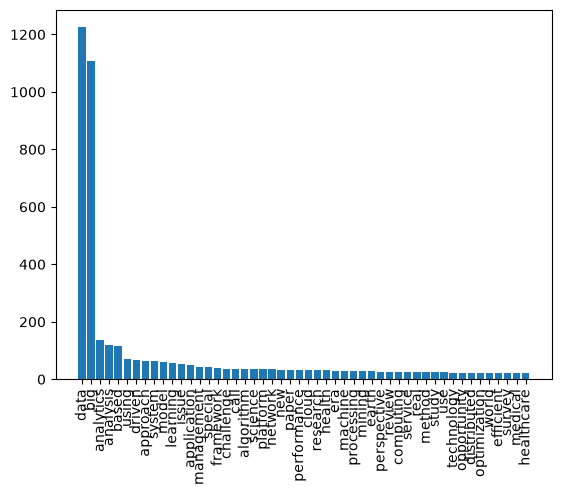

In [27]:
sorted_Keys = sorted(word_count, key = word_count.get, reverse = True) # key = word_count.get: 정렬 기준을 단어의 빈도 수로 설정(word_count.get을 함수 참조로 전달해 내부에서 실행하도록 함)
sorted_Values = sorted(word_count.values(), reverse = True)
plt.bar(range(len(word_count)), sorted_Values, align = 'center') # 50개 이하의 막대그래프 생성. 값은 value 기준.
plt.xticks(range(len(word_count)), list(sorted_Keys), rotation = 'vertical') # 키 값을 틱값으로 설정. 이때 rotation=Vertical로 틱값을 수직으로 배치함.
plt.show()

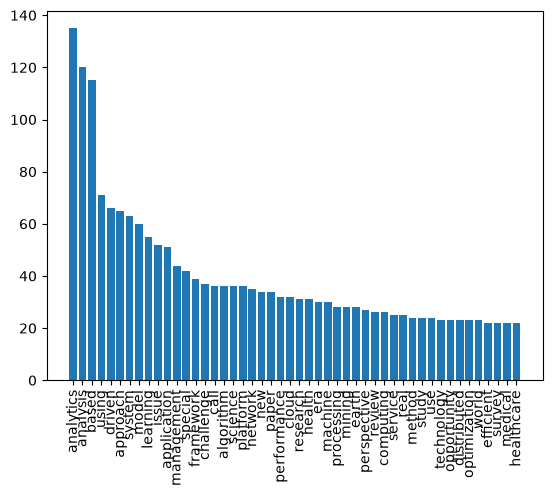

In [28]:
# 특정 단어를 제거한 뒤 막대그래프 그리기
del word_count['big']
del word_count['data']

sorted_Keys = sorted(word_count, key = word_count.get, reverse = True)
sorted_Values = sorted(word_count.values(), reverse = True)
plt.bar(range(len(word_count)), sorted_Values, align = 'center')
plt.xticks(range(len(word_count)), list(sorted_Keys), rotation = 'vertical')
plt.show()

In [7]:
# 빈도수 분석(연도별 연구량)
all_files_data_concat['doc_count'] = 0 # 컬럼 생성하며 0으로 만듦

on_the_way = all_files_data_concat.groupby('출판일', as_index = False) # as_index = False로 '출판일'을 인덱스가 아닌 일반 컬럼으로 설정
print(on_the_way) # DataFrameGroupBy 객체(내부에서 출판일 기준으로 나눠놓음)

summary_year = all_files_data_concat.groupby('출판일', as_index = False)['doc_count'].count() # '출판일'이 그룹화 변수. 인덱스는 0, 1, 2, . '출판일'이 같은 행들에 대해 개수를 세어 summary로 넘김
print(f'type: {type(summary_year)}')

print(summary_year)

type: <class 'pandas.DataFrame'>
     출판일  doc_count
0      -          2
1   2004          1
2   2011          3
3   2012         14
4   2013         44
5   2014         84
6   2015         80
7   2016         99
8   2017        114
9   2018        107
10  2019         86
11  2020        126
12  2021        100
13  2022         78
14  2023         45
15  2024         14
16  2025          3


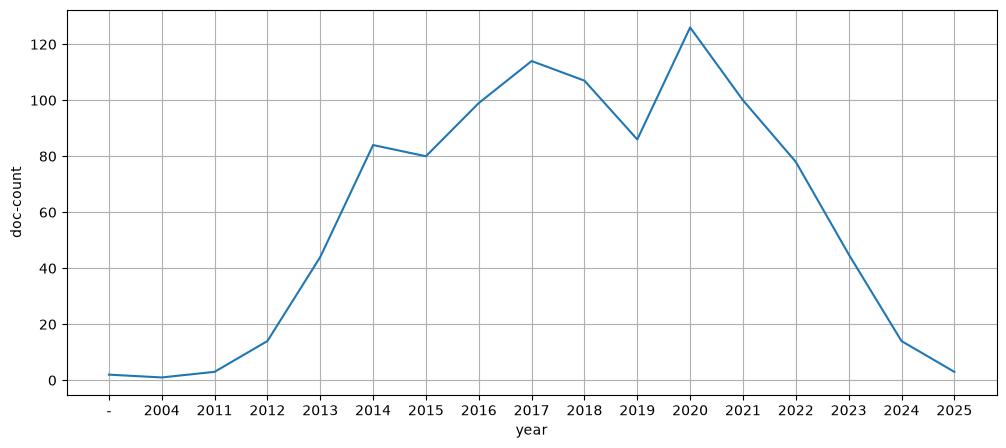

In [32]:
# 그래프 그리기
plt.figure(figsize = (12, 5))
plt.xlabel("year")
plt.ylabel("doc-count")
plt.grid(True)
plt.plot(range(len(summary_year)), summary_year['doc_count'])
plt.xticks(range(len(summary_year)), [text for text in summary_year['출판일']])
plt.show()

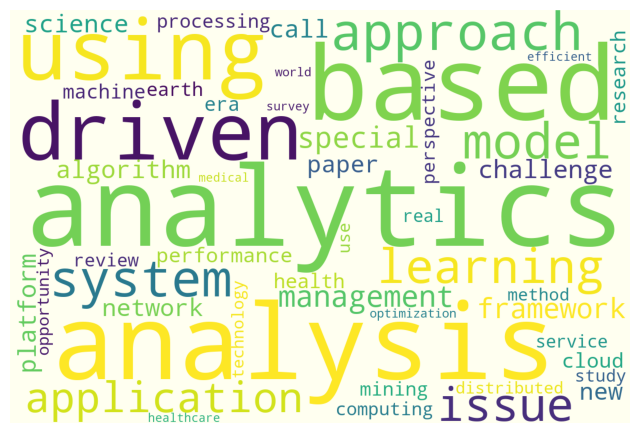

In [33]:
stopwords = set(STOPWORDS)
wc = WordCloud(background_color= 'ivory', stopwords = stopwords, width = 1200, height = 800)
cloud = wc.generate_from_frequencies(word_count) # {단어: 빈도수} 형태의 dict 받아 워드클라우드 생성
plt.figure(figsize = (8,8))
plt.imshow(cloud) # 이미지를 격자 형태로 준비
plt.axis('off') # 축 해제
plt.show() # 출력

In [34]:
cloud.to_file("riss_bigdata_wordCloud.jpg")